In [1]:
%% MIT 18.03 Lecture 18: Engineering Vibrations, Damping Ratio & Tuning
% Description: Simulates engineering applications presented by Prof. Kim Vandiver:
%              1) Standard 2nd-order LTI model parameterized by natural frequency wn and damping ratio zeta.
%              2) Identification via Half-Amplitude Rule: zeta = 0.11 / n_50%.
%              3) Transient decay visualization using Control System Toolbox 'initial'.
%              4) Cantilever frequency ruler tuning curve: wn(L) = 3.706 / L^2.
%
% % Required Toolboxes:
% %   - Control System Toolbox (tf, damp, initial, pole).
%
% % MBD Concept Mapping: Demonstrates standard 2nd-order parameterization: s^2 + 2*zeta*wn*s + wn^2 = 0.
% %                      Validates logarithmic decrement identification in vibration engineering,
% %                      and structural natural frequency tuning for resonance matching.


clear; clc; close all;


%% =========================================================================
%% Part 1: Parameter Identification from Lecture Demo Measurements
%% =========================================================================
% Experimental measurements from Vandiver's lecture demo:
% 10 cycles took 14.2 seconds -> Period P = 1.42 s/cycle
P_measured = 1.42;
n_50 = 4.0; % Number of cycles to reach 50% amplitude


% 1. Damped circular frequency: wd = 2*pi / P
omega_d = 2 * pi / P_measured; % ~ 4.425 rad/s


% 2. Damping ratio estimation via Vandiver's Rule: zeta ~ 0.11 / n_50
zeta_approx = 0.11 / n_50; % ~ 0.0275 (2.75% damping)


% Exact derivation: ln(2) / (2*pi * n_50)
delta_50 = log(2) / n_50;
zeta_exact = delta_50 / sqrt((2*pi)^2 + delta_50^2);


% 3. Undamped natural frequency: wn = wd / sqrt(1 - zeta^2)
omega_n = omega_d / sqrt(1 - zeta_exact^2);


% Construct Standard LTI Model via Control System Toolbox:
% G(s) = wn^2 / (s^2 + 2*zeta*wn*s + wn^2)
num_sys = omega_n^2;
den_sys = [1, 2 * zeta_exact * omega_n, omega_n^2];
sys_lti = tf(num_sys, den_sys);


fprintf('=== Engineering System Identification Diagnostics ===\n');

=== Engineering System Identification Diagnostics ===

In [2]:
fprintf('Measured Period (P)        : %.4f s (f_d = %.3f Hz)\n', P_measured, 1/P_measured);

Measured Period (P)        : 1.4200 s (f_d = 0.704 Hz)

In [3]:
fprintf('Damped Frequency (w_d)     : %.4f rad/s\n', omega_d);

Damped Frequency (w_d)     : 4.4248 rad/s

In [4]:
fprintf('Cycles to 50%% Decay (n_50) : %.1f cycles\n', n_50);

Cycles to 50% Decay (n_50) : 4.0 cycles

In [5]:
fprintf('Approx Damping Ratio (zeta): %.4f (%.2f%% critical)\n', zeta_approx, zeta_approx*100);

Approx Damping Ratio (zeta): 0.0275 (2.75% critical)

In [6]:
fprintf('Exact Damping Ratio (zeta) : %.4f (%.2f%% critical)\n', zeta_exact, zeta_exact*100);

Exact Damping Ratio (zeta) : 0.0276 (2.76% critical)

In [7]:
fprintf('Natural Frequency (w_n)    : %.4f rad/s\n', omega_n);

Natural Frequency (w_n)    : 4.4265 rad/s

In [8]:
fprintf('\n--- Control System Toolbox Modal Analysis (damp) ---\n');

--- Control System Toolbox Modal Analysis (damp) ---

In [9]:
damp(sys_lti);

                                                                       
         Pole              Damping       Frequency      Time Constant  
                                       (rad/seconds)      (seconds)    
                                                                       
 -1.22e-01 + 4.42e+00i     2.76e-02       4.43e+00         8.19e+00    
 -1.22e-01 - 4.42e+00i     2.76e-02       4.43e+00         8.19e+00

In [10]:
fprintf('=====================================================\n\n');


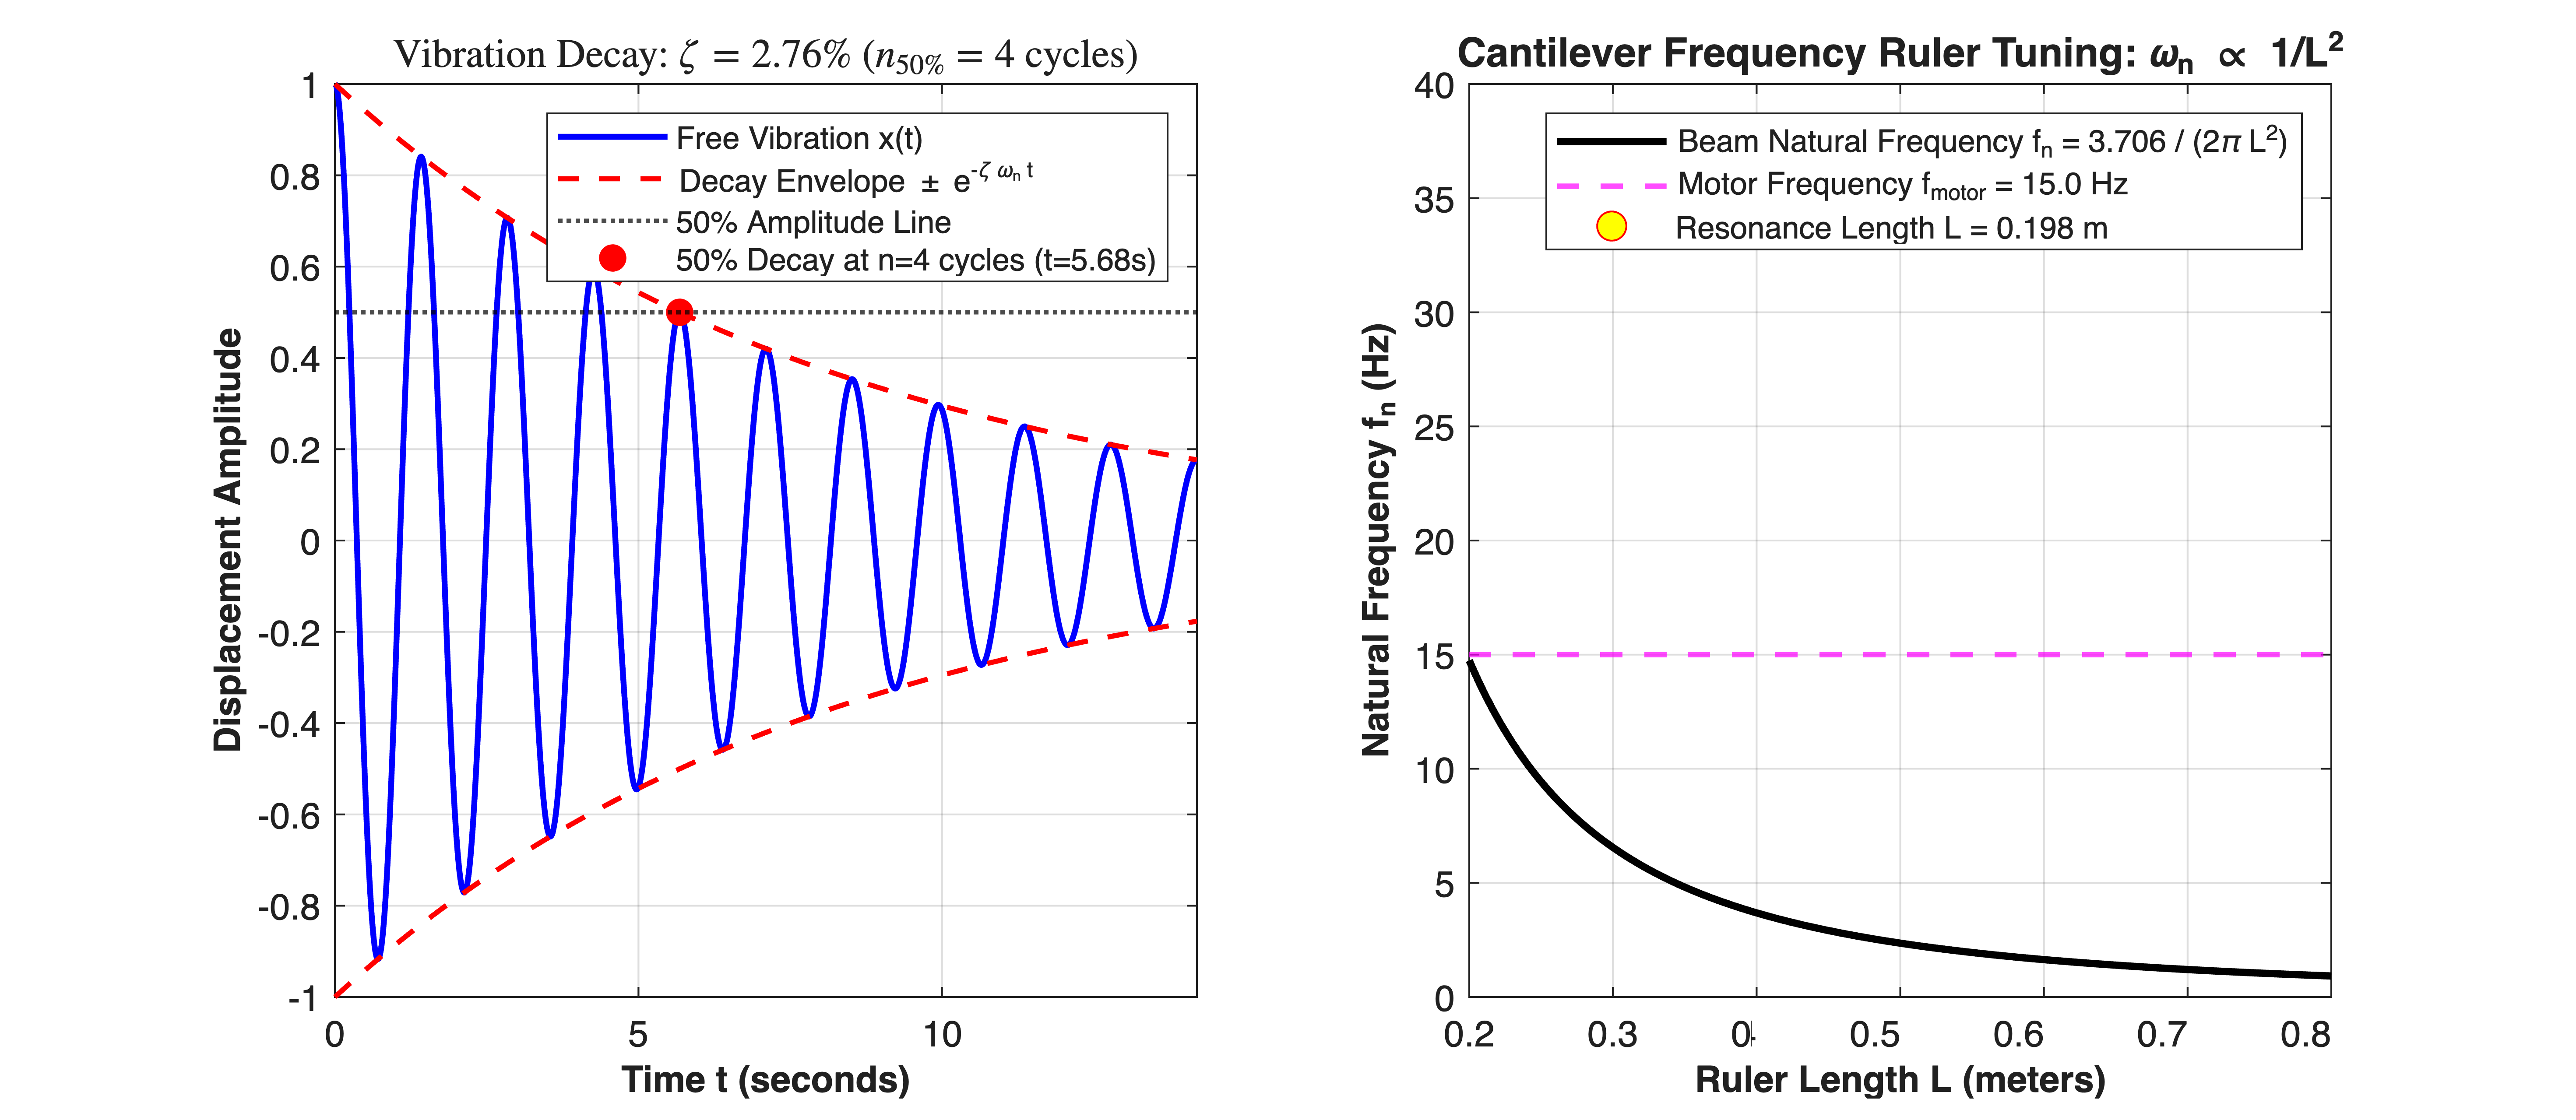

In [11]:


%% =========================================================================
%% Part 2: Time-Domain Envelope & 50% Decay Visualization
%% =========================================================================
t_sim = linspace(0, 10 * P_measured, 1200);
x0 = 1.0; % Initial displacement


% Free vibration response: x(t) = x0 * exp(-zeta*wn*t) * cos(wd*t)
% Using Control System Toolbox 'initial' on standard canonical state-space
A_mat = [0, 1; -omega_n^2, -2*zeta_exact*omega_n];
B_mat = [0; 1];
C_mat = [1, 0];
D_mat = 0;
sys_ss = ss(A_mat, B_mat, C_mat, D_mat);


[x_resp, t_out] = initial(sys_ss, [x0; 0], t_sim);


% Analytical exponential decay envelopes
env_upper =  x0 * exp(-zeta_exact * omega_n * t_sim);
env_lower = -x0 * exp(-zeta_exact * omega_n * t_sim);


% Time of 50% amplitude decay
t_half = n_50 * P_measured;


figure('Color', [1 1 1], 'Position', [100, 100, 1150, 500]);


% Subplot 1: Free Damped Vibration & Logarithmic Envelope
subplot(1, 2, 1);
hold on; grid on; box on;


plot(t_out, x_resp, 'b-', 'LineWidth', 1.6, 'DisplayName', 'Free Vibration x(t)');
plot(t_sim, env_upper, 'r--', 'LineWidth', 1.4, 'DisplayName', 'Decay Envelope \pm e^{-\zeta \omega_n t}');
plot(t_sim, env_lower, 'r--', 'LineWidth', 1.4, 'HandleVisibility', 'off');


% Mark the 50% decay threshold
yline(0.5 * x0, 'k:', 'LineWidth', 1.2, 'DisplayName', '50% Amplitude Line');
plot(t_half, 0.5 * x0, 'ro', 'MarkerFaceColor', 'r', 'MarkerSize', 7, ...
     'DisplayName', sprintf('50%% Decay at n=%.0f cycles (t=%.2fs)', n_50, t_half));


xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Displacement Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title(sprintf('Vibration Decay: $\\zeta = %.2f\\%%$ ($n_{50\\%%} = %d$ cycles)', ...
      zeta_exact*100, n_50), 'FontSize', 11, 'FontWeight', 'bold', 'Interpreter', 'latex');
legend('Location', 'northeast', 'FontSize', 8.5);
xlim([0, 10 * P_measured]);


%% =========================================================================
%% Part 3: Frequency Ruler Resonance Tuning (Lecture Section [3])
%% =========================================================================
% Equation for steel ruler beam: wn = 3.706 / L^2
L_vec = linspace(0.2, 0.8, 300); % Length in meters
wn_ruler = 3.706 ./ (L_vec.^2);  % rad/s
fn_ruler = wn_ruler / (2 * pi);  % Hertz


% Target motor excitation frequency (e.g., cell phone motor / squiggle pen at 15 Hz)
f_motor_target = 15.0; % Hz
L_resonant = sqrt(3.706 / (2 * pi * f_motor_target));


% Subplot 2: Natural Frequency vs Beam Length (Tuning Curve)
subplot(1, 2, 2);
hold on; grid on; box on;


plot(L_vec, fn_ruler, 'k-', 'LineWidth', 2.0, ...
     'DisplayName', 'Beam Natural Frequency f_n = 3.706 / (2\pi L^2)');
yline(f_motor_target, 'm--', 'LineWidth', 1.5, ...
      'DisplayName', sprintf('Motor Frequency f_{motor} = %.1f Hz', f_motor_target));
plot(L_resonant, f_motor_target, 'ro', 'MarkerFaceColor', 'y', 'MarkerSize', 8, ...
     'DisplayName', sprintf('Resonance Length L = %.3f m', L_resonant));


xlabel('Ruler Length L (meters)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('Natural Frequency f_n (Hz)', 'FontSize', 10, 'FontWeight', 'bold');
title('Cantilever Frequency Ruler Tuning: \omega_n \propto 1/L^2', ...
      'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northeast', 'FontSize', 8.5);
ylim([0, 40]);
xlim([0.2, 0.8]);